# Task 4: High-Imbalance Clinical Disease Predictor
**Data:** UCI Thoracic Surgery (470 patients, only about 15% are high-risk)
**Goal:** find as many high-risk patients as possible (high recall) and how reliable the result is.


## Step 1: Install and import

In [1]:
# Install the extra libraries (Colab already has pandas, numpy, scikit-learn, matplotlib)
!pip install -q liac-arff imbalanced-learn xgboost

  Preparing metadata (setup.py) ... done


In [2]:
import pandas as pd                         # pandas: works with tables of data
import numpy as np                          # numpy: maths on numbers
import matplotlib.pyplot as plt             # matplotlib: draws charts
import arff                                 # liac-arff: reads .arff files

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict  # split, cross-validation, tuning
from sklearn.base import clone              # makes a fresh copy of a model
from sklearn.compose import ColumnTransformer                                  # different steps for different columns
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler  # text to numbers, and scaling
from sklearn.svm import SVC                                                    # Support Vector Machine
from sklearn.ensemble import RandomForestClassifier                            # Random Forest
from sklearn.metrics import (recall_score, precision_score, f1_score,          # the scores reported in this notebook
                             roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)
from imblearn.pipeline import Pipeline      # a pipeline that is allowed to contain SMOTE
from imblearn.over_sampling import SMOTENC  # SMOTE that understands category columns
from xgboost import XGBClassifier           # XGBoost model
from scipy.stats import binomtest           # gives a confidence interval for recall

## Step 2: Load the data
Run arff file (`ThoraricSurgery.arff`, any file name works).
If you do not have the file, run instead (it downloads it from UCI). Run only one of them.

In [3]:
# OPTION A: upload the file from your computer
from google.colab import files              # Colab tool for uploading files
uploaded = files.upload()                   # a button appears: choose ThoracicSurgery.arff
file_name = list(uploaded.keys())[0]        # remember the name of the uploaded file

Saving ThoraricSurgery.arff to ThoraricSurgery.arff


In [4]:
with open(file_name, "r") as f:                                                       # open the ARFF file
    dataset = arff.load(f)                                                            # read it with liac-arff
data = pd.DataFrame(dataset["data"], columns=[a[0] for a in dataset["attributes"]])   # make a table, column names come from the file
print(data.shape)                                                                     # should print (470, 17)
data.head()                                                                           # show the first 5 patients

(470, 17)


,DGN,PRE4,PRE5,PRE6,PRE7,PRE8,PRE9,PRE10,PRE11,PRE14,PRE17,PRE19,PRE25,PRE30,PRE32,AGE,Risk1Yr
0,DGN2,2.88,2.16,PRZ1,F,F,F,T,T,OC14,F,F,F,T,F,60.0,F
1,DGN3,3.40,1.88,PRZ0,F,F,F,F,F,OC12,F,F,F,T,F,51.0,F
2,DGN3,2.76,2.08,PRZ1,F,F,F,T,F,OC11,F,F,F,T,F,59.0,F
3,DGN3,3.68,3.04,PRZ0,F,F,F,F,F,OC11,F,F,F,F,F,54.0,F
4,DGN3,2.44,0.96,PRZ2,F,T,F,T,T,OC11,F,F,F,T,F,73.0,T


## Step 3: Look at the target (how imbalanced is it?)

In [5]:
data["Target"] = data["Risk1Yr"].map({"F": 0, "T": 1})        # F = survived (0), T = died within 1 year (1)
print(data["Target"].value_counts())                          # how many patients in each class
print(data["Target"].value_counts(normalize=True).round(3))   # the same as fractions
print("Missing values:", data.isnull().sum().sum())           # should be 0

Target
0    400
1     70
Name: count, dtype: int64
Target
0    0.851
1    0.149
Name: proportion, dtype: float64
Missing values: 0


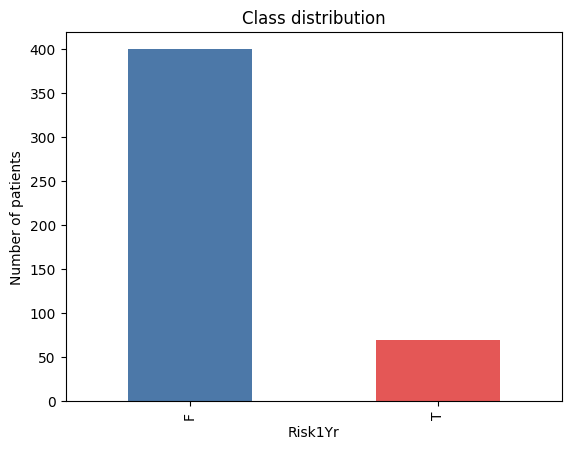

In [6]:
data["Risk1Yr"].value_counts().plot(kind="bar", color=["#4C78A8", "#E45756"])  # bar chart of the two classes
plt.title("Class distribution")                                                # chart title
plt.ylabel("Number of patients")                                               # y-axis label
plt.show()                                                                     # draw the chart

## Step 4: Split into train and test


In [7]:
X = data.drop(columns=["Risk1Yr", "Target"])     # the 16 clinical features
y = data["Target"]                               # the answer to predict
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,        # 20% of patients go to the test set
    random_state=42,       # same split every time the notebook runs
    stratify=y)            # keep the same 15% high-risk share in both parts
print("Train:", X_train.shape, "high-risk:", y_train.sum())   # train size and number of high-risk patients
print("Test: ", X_test.shape,  "high-risk:", y_test.sum())    # test size and number of high-risk patients

Train: (376, 16) high-risk: 56
Test:  (94, 16) high-risk: 14


## Step 5: Build the pipeline (encode, SMOTENC, scale, model)
Everything happens **inside** the pipeline, so SMOTENC only ever touches training data, also inside cross-validation.

In [8]:
num_cols = ["PRE4", "PRE5", "AGE"]                                  # the 3 numeric columns
cat_cols = [c for c in X.columns if c not in num_cols]              # every other column is a category (13 columns)
cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols))) # position of category columns after Step A (numbers come first)
print("Numeric:", num_cols)                                         # check numeric list
print("Categorical:", len(cat_cols), "columns")                     # check how many categories

Numeric: ['PRE4', 'PRE5', 'AGE']
Categorical: 13 columns


In [9]:
def make_pipeline(model):
    # Step A: numbers stay as they are, categories become integer codes (SMOTENC needs this)
    encode = ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)])
    # Step C: scale the numbers, and one-hot encode the categories for the model
    scale_onehot = ColumnTransformer([
        ("num", StandardScaler(), list(range(len(num_cols)))),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_idx)])
    return Pipeline([
        ("encode", encode),                                                   # Step A
        ("smote", SMOTENC(categorical_features=cat_idx, random_state=42)),    # Step B: add synthetic high-risk patients (train only)
        ("scale_onehot", scale_onehot),                                       # Step C
        ("model", model)])                                                    # Step D: the classifier

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # 5 folds, each keeps the 15% high-risk share
scoring = {"recall": "recall", "roc_auc": "roc_auc", "pr_auc": "average_precision"}   # scores to record in every fold

def show_cv(search, name):
    i = search.best_index_                                                         # position of the best setting
    folds = [search.cv_results_[f"split{k}_test_recall"][i] for k in range(5)]     # recall in each of the 5 folds
    print(name)                                                                    # model name
    print("  best settings :", search.best_params_)                                # best hyperparameters
    print("  CV recall     : %.3f (+/- %.3f)" % (search.cv_results_["mean_test_recall"][i], search.cv_results_["std_test_recall"][i]))  # mean and spread
    print("  CV ROC-AUC    : %.3f" % search.cv_results_["mean_test_roc_auc"][i])   # ranking quality
    print("  CV PR-AUC     : %.3f" % search.cv_results_["mean_test_pr_auc"][i])    # precision-recall quality
    print("  fold recalls  :", np.round(folds, 2))                                 # each fold

## Step 6: Tune SVM

In [11]:
svm_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],        # from very soft (0.01) to very strict (100) margins
    "model__kernel": ["rbf", "linear"],         # curved or straight boundary
    "model__gamma": ["scale", "auto"]}          # only used by rbf
svm_search = GridSearchCV(make_pipeline(SVC(random_state=42)), svm_grid,
                          scoring=scoring, refit="recall", cv=cv, n_jobs=-1)   # choose the setting with best recall
svm_search.fit(X_train, y_train)                # train and test every setting with 5-fold CV
show_cv(svm_search, "SVM")                      # print the result

SVM
  best settings : {'model__C': 0.01, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
  CV recall     : 0.823 (+/- 0.170)
  CV ROC-AUC    : 0.517
  CV PR-AUC     : 0.204
  fold recalls  : [0.75 0.55 1.   0.82 1.  ]


## Step 7: Tune Random Forest

In [12]:
rf_grid = {
    "model__n_estimators": [100, 300],          # number of trees
    "model__max_depth": [None, 5, 10],          # tree depth (smaller = simpler)
    "model__min_samples_split": [2, 5],         # minimum patients to split a node
    "model__class_weight": [None, "balanced"]}  # give more weight to the rare class or not
rf_search = GridSearchCV(make_pipeline(RandomForestClassifier(random_state=42)), rf_grid,
                         scoring=scoring, refit="recall", cv=cv, n_jobs=-1)
rf_search.fit(X_train, y_train)                 # train and test every setting
show_cv(rf_search, "Random Forest")             # print the result

Random Forest
  best settings : {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_split': 5, 'model__n_estimators': 100}
  CV recall     : 0.395 (+/- 0.128)
  CV ROC-AUC    : 0.542
  CV PR-AUC     : 0.220
  fold recalls  : [0.25 0.36 0.55 0.27 0.55]


## Step 8: Tune XGBoost

In [13]:
xgb_grid = {
    "model__n_estimators": [100, 200],          # number of boosting rounds
    "model__max_depth": [2, 3, 5],              # tree depth
    "model__learning_rate": [0.05, 0.1],        # step size
    "model__subsample": [0.8, 1.0]}             # share of rows used per tree
xgb_search = GridSearchCV(make_pipeline(XGBClassifier(random_state=42, eval_metric="logloss")), xgb_grid,
                          scoring=scoring, refit="recall", cv=cv, n_jobs=-1)
xgb_search.fit(X_train, y_train)                # train and test every setting
show_cv(xgb_search, "XGBoost")                  # print the result

XGBoost
  best settings : {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 1.0}
  CV recall     : 0.395 (+/- 0.099)
  CV ROC-AUC    : 0.531
  CV PR-AUC     : 0.210
  fold recalls  : [0.25 0.36 0.55 0.36 0.45]


## Step 9: Compare the three models using cross-validation only

In [14]:
searches = {"SVM": svm_search, "Random Forest": rf_search, "XGBoost": xgb_search}     # the three tuned models
rows = []                                                                              # one row per model
for name, s in searches.items():
    i = s.best_index_                                                                  # best setting position
    rows.append({"Model": name,
                 "CV recall": s.cv_results_["mean_test_recall"][i],
                 "CV ROC-AUC": s.cv_results_["mean_test_roc_auc"][i],
                 "CV PR-AUC": s.cv_results_["mean_test_pr_auc"][i]})
cv_table = pd.DataFrame(rows).round(3)                                                 # make a table
print("Share of high-risk patients (a random model's PR-AUC):", round(y_train.mean(), 3))  # the PR-AUC baseline
cv_table                                                                               # show it

Share of high-risk patients (a random model's PR-AUC): 0.149


,Model,CV recall,CV ROC-AUC,CV PR-AUC
0,SVM,0.823,0.517,0.204
1,Random Forest,0.395,0.542,0.220
2,XGBoost,0.395,0.531,0.210


## Step 10: Final test
The model with the best **CV recall** is selected (the task rule) and tested once on the 94 locked test patients.

In [15]:
def get_scores(model, X_data):
    if hasattr(model, "predict_proba"):                 # Random Forest and XGBoost give probabilities
        return model.predict_proba(X_data)[:, 1]
    return model.decision_function(X_data)             # SVM gives a distance score instead

def test_report(name, model):
    pred = model.predict(X_test)                        # predicted classes (0 or 1)
    score = get_scores(model, X_test)                   # scores for the AUC numbers
    return {"Model": name,
            "Recall": recall_score(y_test, pred),                        # share of high-risk patients found
            "Precision": precision_score(y_test, pred, zero_division=0), # share of flagged patients who are really high-risk
            "F1": f1_score(y_test, pred, zero_division=0),               # balance of the two
            "ROC-AUC": roc_auc_score(y_test, score),                     # ranking quality
            "PR-AUC": average_precision_score(y_test, score)}            # precision-recall quality

results = [test_report(n, s.best_estimator_) for n, s in searches.items()]   # the three models on the test set
prev = y_test.mean()                                                          # share of high-risk patients in the test set
results.append({"Model": "Baseline: flag everyone", "Recall": 1.0, "Precision": prev,
                "F1": 2 * prev / (1 + prev), "ROC-AUC": 0.5, "PR-AUC": prev})  # a model with no skill
test_table = pd.DataFrame(results).round(3)                                   # make a table
test_table                                                                    # show it

,Model,Recall,Precision,F1,ROC-AUC,PR-AUC
0,SVM,0.857,0.156,0.264,0.633,0.236
1,Random Forest,0.643,0.225,0.333,0.601,0.192
2,XGBoost,0.571,0.222,0.320,0.634,0.245
3,Baseline: flag everyone,1.000,0.149,0.259,0.500,0.149


Selected model: SVM
True neg: 15 | False pos: 65 | False neg: 2 | True pos: 12
Recall = 12/14 = 0.86, 95% interval 0.60 to 0.96
Patients flagged as high-risk: 77 out of 94


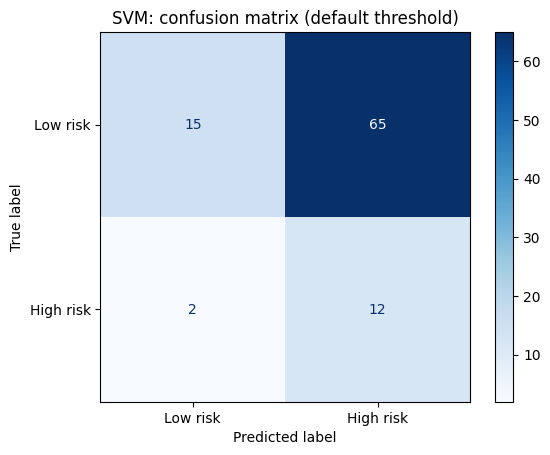

In [16]:
best_name = cv_table.sort_values("CV recall", ascending=False).iloc[0]["Model"]   # model with the best CV recall
final_model = searches[best_name].best_estimator_                                 # its trained pipeline
print("Selected model:", best_name)                                               # say which one
cm = confusion_matrix(y_test, final_model.predict(X_test))                        # counts of right and wrong
tn, fp, fn, tp = cm.ravel()                                                       # unpack the four numbers
print("True neg:", tn, "| False pos:", fp, "| False neg:", fn, "| True pos:", tp) # print them
ci = binomtest(int(tp), int(tp + fn)).proportion_ci(confidence_level=0.95, method="wilson")  # 95% interval for recall
print(f"Recall = {tp}/{tp+fn} = {tp/(tp+fn):.2f}, 95% interval {ci.low:.2f} to {ci.high:.2f}")  # a wide interval = uncertain
print("Patients flagged as high-risk:", tp + fp, "out of", len(y_test))           # how many people the model flags
ConfusionMatrixDisplay(cm, display_labels=["Low risk", "High risk"]).plot(cmap="Blues")  # draw the confusion matrix
plt.title(f"{best_name}: confusion matrix (default threshold)")                   # chart title
plt.show()                                                                        # show the chart

## Step 11: Threshold tuning (chosen on training data only)
The model normally says "high-risk" above a fixed cut-off. A better cut-off is chosen using out-of-fold scores from the **training** data and then tested once.

In [17]:
method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"   # how this model gives scores
oof = cross_val_predict(clone(final_model), X_train, y_train, cv=cv, method=method)          # scores for training patients, each from a model that did not see them
oof = oof[:, 1] if oof.ndim == 2 else oof                                                    # keep the high-risk column
prec, rec, thr = precision_recall_curve(y_train, oof)        # precision and recall at every cut-off
ok = np.where(rec[:-1] >= 0.80)[0]                           # cut-offs that find at least 80% of high-risk patients
pick = ok[np.argmax(prec[:-1][ok])]                          # among them, take the one with the best precision
threshold = thr[pick]                                        # the chosen cut-off
print("Chosen cut-off:", round(float(threshold), 3))         # show it
new_pred = (get_scores(final_model, X_test) >= threshold).astype(int)   # apply it to the test patients
print("Test recall   :", round(recall_score(y_test, new_pred), 3))      # high-risk patients found
print("Test precision:", round(precision_score(y_test, new_pred, zero_division=0), 3))  # flagged patients who are truly high-risk
print("Flagged       :", int(new_pred.sum()), "of", len(y_test))        # how many patients are flagged

Chosen cut-off: 0.019
Test recall   : 0.857
Test precision: 0.179
Flagged       : 67 of 94


## Step 12: Chart and save

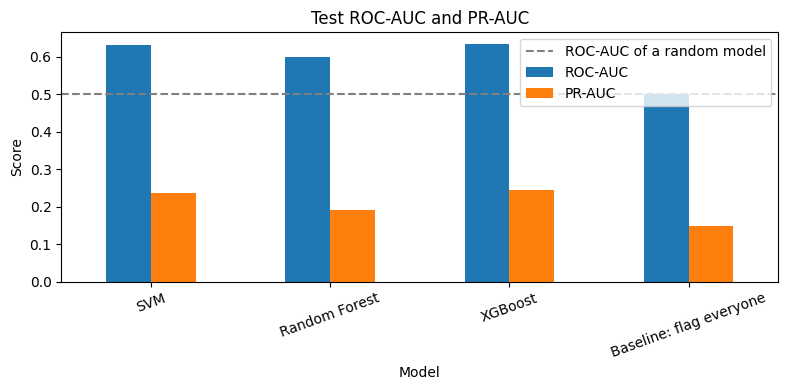

In [18]:
plot_df = test_table.set_index("Model")[["ROC-AUC", "PR-AUC"]]       # the two ranking scores
plot_df.plot(kind="bar", figsize=(8, 4))                             # grouped bar chart
plt.axhline(0.5, color="grey", linestyle="--", label="ROC-AUC of a random model")   # the no-skill line for ROC-AUC
plt.ylabel("Score")                                                  # y-axis label
plt.title("Test ROC-AUC and PR-AUC")                                 # title
plt.xticks(rotation=20)                                              # tilt the names
plt.legend()                                                         # show legend
plt.tight_layout()                                                   # tidy the layout
plt.show()                                                           # draw it

In [19]:
test_table.to_csv("model_comparison_results.csv", index=False)       # save the table
from google.colab import files
files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

**Result table (94 locked test patients, 14 of them high-risk)**

| Model | CV recall | CV ROC-AUC | Test recall | Test precision | Test F1 | Test ROC-AUC | Test PR-AUC |
|---|---|---|---|---|---|---|---|
| SVM | 0.823 | 0.517 | 0.857 | 0.156 | 0.264 | 0.633 | 0.236 |
| Random Forest | 0.395 | 0.542 | 0.643 | 0.225 | 0.333 | 0.601 | 0.192 |
| XGBoost | 0.395 | 0.531 | 0.571 | 0.222 | 0.320 | 0.634 | 0.245 |
| Baseline: flag everyone | - | - | 1.000 | 0.149 | 0.259 | 0.500 | 0.149 |

1. **Model chosen by the task rule (best CV recall): SVM** (C=0.01, RBF). CV recall 0.823 (+/- 0.170). On the test set it found 12 of 14 high-risk patients (recall 0.86, 95% interval 0.60 to 0.96).
2. **But this SVM is almost the same as "flag everyone".** It flagged 77 of 94 patients, its precision (0.156) is barely above the share of high-risk patients (0.149), its CV ROC-AUC (0.517) is close to a random model (0.5), and its F1 (0.264) equals the baseline (0.259). Tuning for recall alone rewards a model that flags almost everybody.
3. **Random Forest and XGBoost find fewer patients but flag far fewer people.** They found 9 and 8 of 14 high-risk patients while flagging about 40 and 36 patients, with precision about 1.5 times the base rate. XGBoost has the best test PR-AUC (0.245) and ROC-AUC (0.634); Random Forest has the best F1 (0.333). Their recall intervals overlap widely (RF 0.39 to 0.84, XGBoost 0.33 to 0.79), so the difference between the models is not reliable.
4. **The overall signal in this data is weak.** CV ROC-AUC is only 0.52 to 0.54 and test ROC-AUC is 0.60 to 0.63. Moving the cut-off to reach 80% recall (Step 11) flagged 67 of 94 patients with precision 0.179.
5. **Limits:** only 470 patients and 14 high-risk test patients, one train/test split, and a large spread between CV folds. This is a learning project, not a clinical tool.
6. **Next steps:** repeated cross-validation, choose the model by precision at an agreed recall level instead of recall alone, more data, and feature importance (for example SHAP).
